# Nigerian Equipment Marketplace Analysis

Part of a three-task project on one dataset: Task 1 collection, Task 2 exploratory data analysis, **Task 3 data visualization**.

**Business Question (whole project):** What does the marketplace's listed equipment inventory reveal about category representation, geographic concentration, and advertised price availability, and how can these insights support marketplace planning?

**Objective:** Turn the cleaned dataset into charts and a summary dashboard that show where listings are concentrated, which categories dominate, and how often prices are listed.

**Input:** `nigerian_equipment_marketplace_cleaned.csv` from Task 2 (158 equipment listings).

**Output:** seven charts and a summary dashboard (eight images), saved in the `charts` folder.


## Task 3: Data Visualization


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, NullFormatter

os.makedirs("charts", exist_ok=True)

df_analysis = pd.read_csv("nigerian_equipment_marketplace_cleaned.csv")

# Brand palette: green version (from equipmentmarket.ng)
GREEN = "#0c9103"
GREEN_MID = "#66b85f"
GREEN_LIGHT = "#b3dcaf"
GREEN_DARK = "#0a5a03"
GREY = "#555555"
brand_cmap = LinearSegmentedColormap.from_list("brand_green", ["#ffffff", GREEN])

print(df_analysis.shape)

(158, 21)


### Chart 1: Equipment Listings by Category

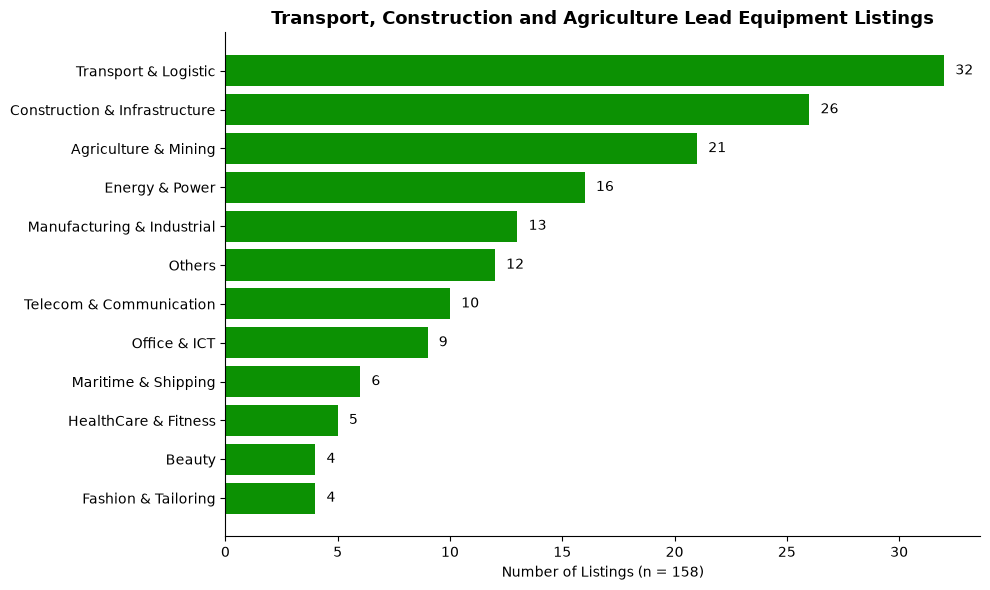

In [2]:
category_counts = (
    df_analysis["category"]
    .str.strip()
    .replace({"Construction & Infrastruture": "Construction & Infrastructure"})
    .value_counts()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(category_counts.index, category_counts.values, color=GREEN)

for bar in bars:
    ax.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        int(bar.get_width()),
        va="center"
    )

ax.set_title("Transport, Construction and Agriculture Lead Equipment Listings", fontsize=13, weight="bold")
ax.set_xlabel("Number of Listings (n = 158)")
ax.set_ylabel("")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("charts/01_listings_by_category.png", dpi=200)
plt.show()

**Insight:** Transport & Logistic (32), Construction & Infrastructure (26) and Agriculture & Mining (21) together account for 79 of 158 listings (50%). This describes the collected listings, not total market supply.

### Chart 2: Equipment Listings by Region

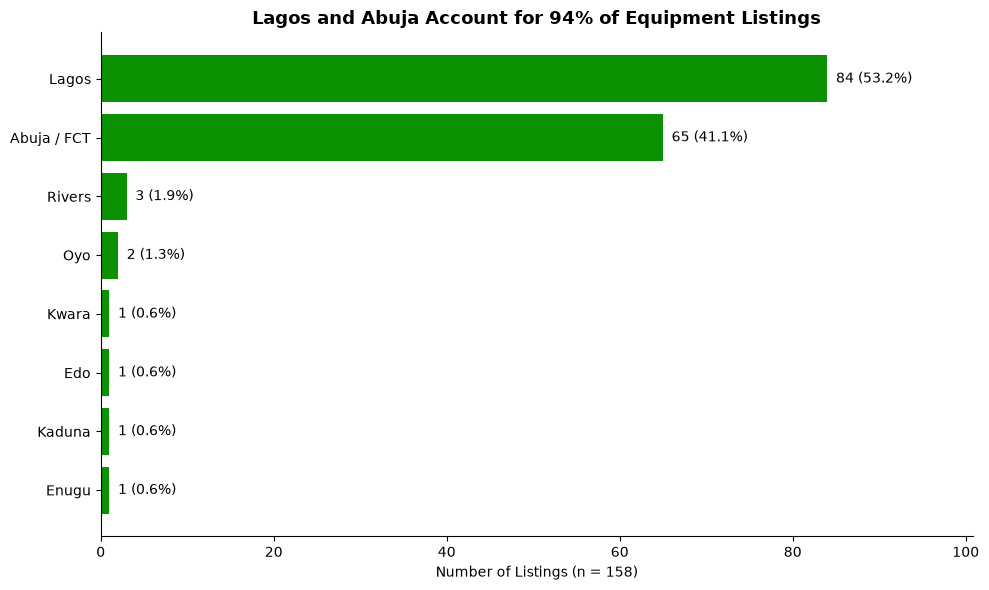

In [3]:
region_counts = df_analysis["region"].value_counts().sort_values()
total = region_counts.sum()

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(region_counts.index, region_counts.values, color=GREEN)

for bar in bars:
    count = int(bar.get_width())
    ax.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{count} ({count / total * 100:.1f}%)",
        va="center"
    )

ax.set_title("Lagos and Abuja Account for 94% of Equipment Listings", fontsize=13, weight="bold")
ax.set_xlabel("Number of Listings (n = 158)")
ax.set_ylabel("")
ax.set_xlim(0, region_counts.max() * 1.2)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("charts/02_listings_by_region.png", dpi=200)
plt.show()

**Insight:** Lagos (84 listings, 53.2%) and Abuja / FCT (65, 41.1%) together account for 149 of 158 listings (94.3%). The remaining six states, including Rivers (3) and Oyo (2), have 9 listings between them. This reflects where listings were advertised on this platform, not where equipment actually exists or where demand is.

### Chart 3: Equipment Listings by Condition

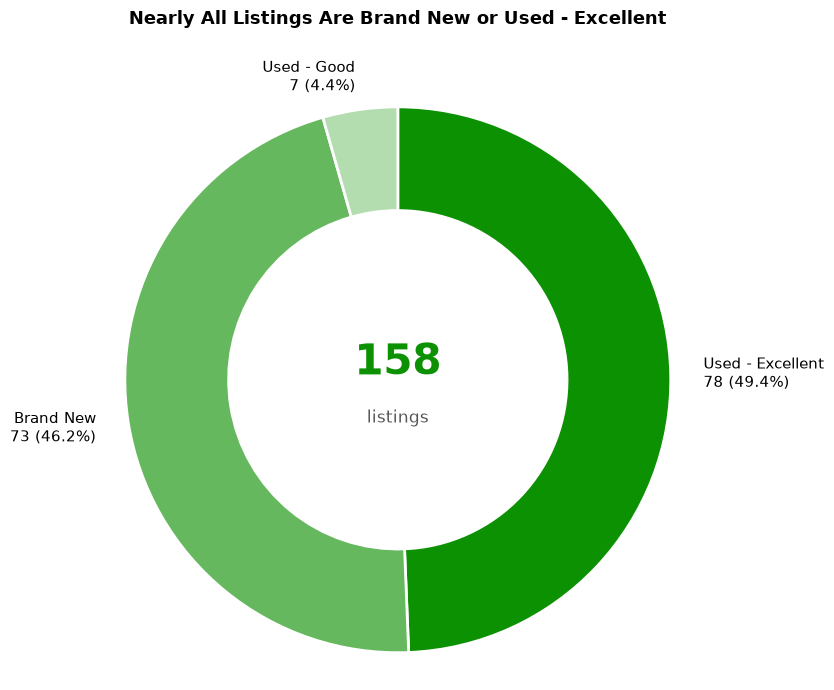

In [4]:
condition_counts = df_analysis["condition"].str.strip().value_counts()
total = condition_counts.sum()

condition_labels = [
    f"{name}\n{int(count)} ({count / total * 100:.1f}%)"
    for name, count in condition_counts.items()
]

fig, ax = plt.subplots(figsize=(8, 7))
ax.pie(
    condition_counts.values,
    labels=condition_labels,
    colors=[GREEN, GREEN_MID, GREEN_LIGHT],
    startangle=90,
    counterclock=False,
    labeldistance=1.12,
    textprops={"fontsize": 11},
    wedgeprops=dict(width=0.38, edgecolor="white", linewidth=2)
)

ax.text(0, 0.06, f"{total}", ha="center", va="center",
        fontsize=30, weight="bold", color=GREEN)
ax.text(0, -0.14, "listings", ha="center", va="center",
        fontsize=12, color=GREY)

ax.set_title("Nearly All Listings Are Brand New or Used - Excellent",
             fontsize=13, weight="bold", pad=40)
ax.axis("equal")

plt.tight_layout()
plt.savefig("charts/03_listings_by_condition.png", dpi=200, bbox_inches="tight")
plt.show()

**Insight:** Used - Excellent (78 listings, 49.4%) and Brand New (73, 46.2%) make up 95.6% of listings, while only 7 listings (4.4%) are marked Used - Good. These conditions are as reported by sellers and were not independently verified, so the near-absence of lower-condition equipment may reflect how sellers describe their items rather than actual equipment quality.

### Chart 4: Price Availability Across Equipment Listings

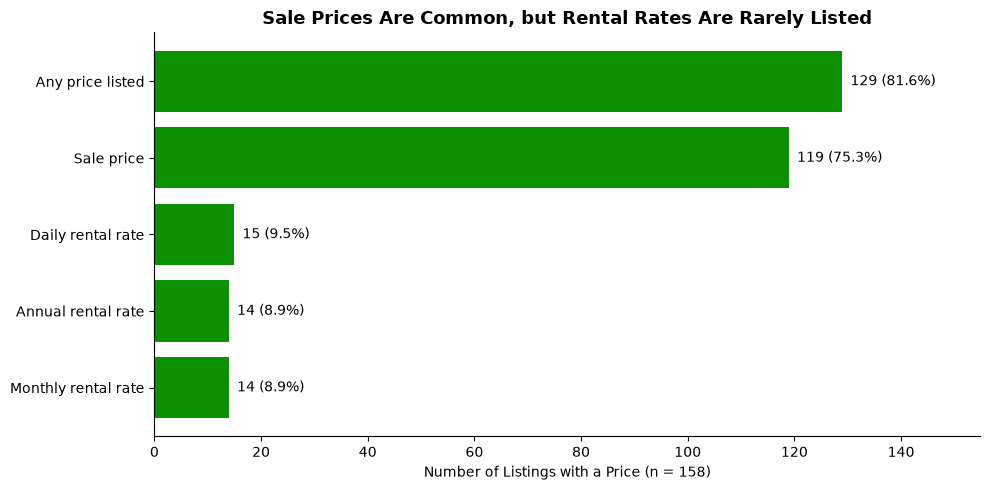

In [5]:
price_cols = ["sale_price", "daily_rate", "monthly_rate", "annual_rate"]
total = len(df_analysis)

availability = {
    "Any price listed": df_analysis[price_cols].notna().any(axis=1).sum(),
    "Sale price": df_analysis["sale_price"].notna().sum(),
    "Daily rental rate": df_analysis["daily_rate"].notna().sum(),
    "Monthly rental rate": df_analysis["monthly_rate"].notna().sum(),
    "Annual rental rate": df_analysis["annual_rate"].notna().sum(),
}
availability = dict(sorted(availability.items(), key=lambda item: item[1]))

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(list(availability.keys()), list(availability.values()), color=GREEN)

for bar in bars:
    count = int(bar.get_width())
    ax.text(
        bar.get_width() + 1.5,
        bar.get_y() + bar.get_height() / 2,
        f"{count} ({count / total * 100:.1f}%)",
        va="center"
    )

ax.set_title("Sale Prices Are Common, but Rental Rates Are Rarely Listed", fontsize=13, weight="bold")
ax.set_xlabel("Number of Listings with a Price (n = 158)")
ax.set_ylabel("")
ax.set_xlim(0, max(availability.values()) * 1.2)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("charts/04_price_availability.png", dpi=200)
plt.show()

**Insight:** 129 of 158 listings (81.6%) show at least one price, and 119 (75.3%) show a sale price. Rental rates are rare: only 15 listings (9.5%) show a daily rate, and 14 (8.9%) show monthly and annual rates. The remaining 29 listings (18.4%) show no price at all. A missing price means the seller did not advertise one, not that the item is free or unavailable, so any price analysis here covers only the listings that disclose prices.

### Chart 5: Distribution of Advertised Sale Prices

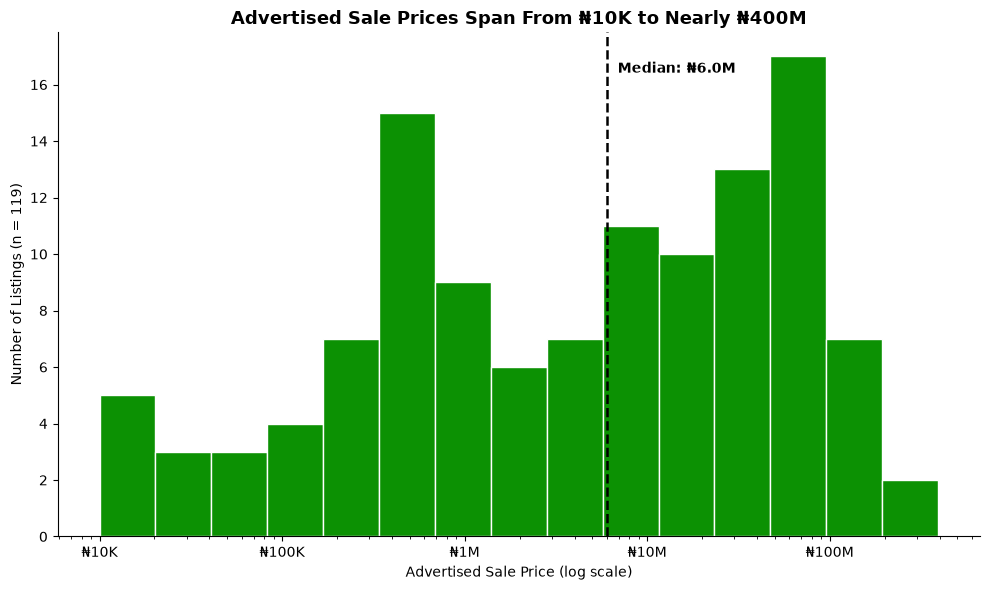

In [6]:
sale_prices = df_analysis["sale_price"].dropna()
median_price = sale_prices.median()

bins = np.logspace(np.log10(sale_prices.min()), np.log10(sale_prices.max()), 16)

fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(sale_prices, bins=bins, color=GREEN, edgecolor="white")
ax.set_xscale("log")

ax.axvline(median_price, color="black", linestyle="--", linewidth=1.8)
ax.text(
    median_price * 1.15,
    ax.get_ylim()[1] * 0.92,
    f"Median: ₦{median_price / 1e6:.1f}M",
    color="black",
    weight="bold"
)

def naira_label(x, pos):
    if x >= 1e6:
        return f"₦{x / 1e6:g}M"
    return f"₦{x / 1e3:g}K"

ax.xaxis.set_major_formatter(FuncFormatter(naira_label))

ax.set_title("Advertised Sale Prices Span From ₦10K to Nearly ₦400M", fontsize=13, weight="bold")
ax.set_xlabel("Advertised Sale Price (log scale)")
ax.set_ylabel(f"Number of Listings (n = {len(sale_prices)})")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("charts/05_sale_price_distribution.png", dpi=200)
plt.show()

**Insight:** Among the 119 listings with a sale price, the median is ₦6.0M while the mean is about ₦30.2M. The mean is five times the median because a small number of very expensive listings pull it up, including six potential outliers flagged by the IQR method (all retained). Prices span four orders of magnitude, from ₦10,000 to ₦392.45M, which reflects the wide mix of equipment, from small items to heavy machinery. These are advertised prices, not confirmed transaction prices, and the median describes this sample only.

### Chart 6: Median Advertised Sale Price by Category

Categories excluded (fewer than 5 priced listings):
           category  median_price  n
             Beauty      161000.0  4
Fashion & Tailoring      107500.0  4
             Others       50000.0  1

Chart data:
                     category  median_price  n
         HealthCare & Fitness       45000.0  5
      Telecom & Communication      445000.0  9
                 Office & ICT      850000.0  9
   Manufacturing & Industrial      920000.0 13
               Energy & Power     2800000.0 16
          Maritime & Shipping     6675000.0  6
         Transport & Logistic    38000000.0 25
         Agriculture & Mining    51000000.0 21
Construction & Infrastructure    70000000.0  6


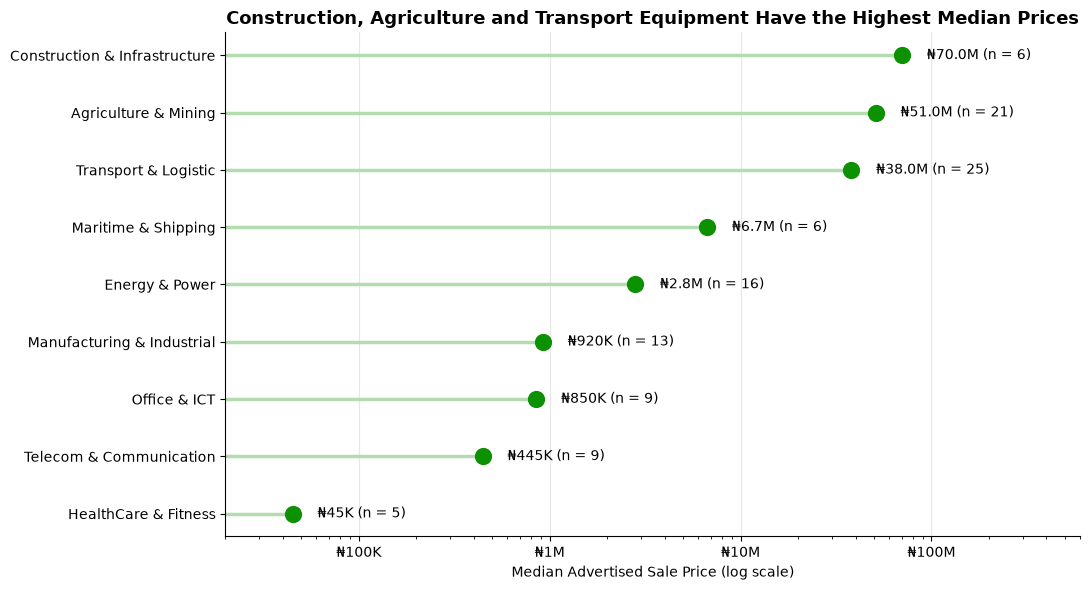

In [7]:
df_price = df_analysis.dropna(subset=["sale_price"]).copy()

df_price["category"] = (
    df_price["category"]
    .str.strip()
    .replace({"Construction & Infrastruture": "Construction & Infrastructure"})
)

category_prices = (
    df_price.groupby("category")["sale_price"]
    .agg(median_price="median", n="count")
    .reset_index()
)

MIN_LISTINGS = 5
excluded = category_prices[category_prices["n"] < MIN_LISTINGS]
plot_data = category_prices[category_prices["n"] >= MIN_LISTINGS].sort_values("median_price")

print("Categories excluded (fewer than 5 priced listings):")
print(excluded.to_string(index=False))
print("\nChart data:")
print(plot_data.to_string(index=False))

def money(v):
    return f"₦{v / 1e6:.1f}M" if v >= 1e6 else f"₦{v / 1e3:.0f}K"

def naira_axis(x, pos):
    return f"₦{x / 1e6:g}M" if x >= 1e6 else f"₦{x / 1e3:g}K"

y_pos = range(len(plot_data))
values = plot_data["median_price"].values
x_min, x_max = 2e4, 6e8

fig, ax = plt.subplots(figsize=(11, 6))
ax.set_axisbelow(True)
ax.grid(axis="x", color="#e6e6e6", linewidth=0.8)
ax.hlines(y_pos, xmin=x_min, xmax=values, color=GREEN_LIGHT, linewidth=2.5)
ax.scatter(values, y_pos, color=GREEN, s=130, zorder=3)

for y, v, n in zip(y_pos, values, plot_data["n"]):
    ax.text(v * 1.35, y, f"{money(v)} (n = {n})", va="center", fontsize=10)

ax.set_xscale("log")
ax.set_xlim(x_min, x_max)
ax.set_yticks(list(y_pos))
ax.set_yticklabels(plot_data["category"])
ax.xaxis.set_major_formatter(FuncFormatter(naira_axis))
ax.xaxis.set_minor_formatter(NullFormatter())

ax.set_title("Construction, Agriculture and Transport Equipment Have the Highest Median Prices", fontsize=13, weight="bold")
ax.set_xlabel("Median Advertised Sale Price (log scale)")
ax.set_ylabel("")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("charts/06_median_price_by_category.png", dpi=200)
plt.show()

**Insight:** Median advertised sale prices differ enormously by category. Construction & Infrastructure has the highest median (₦70.0M), followed by Agriculture & Mining (₦51.0M) and Transport & Logistic (₦38.0M). At the other end, HealthCare & Fitness (₦45K), Telecom & Communication (₦445K) and Office & ICT (₦850K) have the lowest, a gap of more than 1,500 times between the highest and lowest medians. Sample sizes matter here: Construction & Infrastructure, Maritime & Shipping and HealthCare & Fitness each rest on only 5-6 priced listings, so their medians are indicative only. Beauty, Fashion & Tailoring and Others (9 priced listings combined) were excluded for having fewer than 5 priced listings. These are advertised prices, not transaction prices. The x-axis is logarithmic: each gridline is ten times the previous one, so equal distances represent equal ratios, not equal amounts.

### Chart 7: Equipment Listings by Category and Region

region_group                   Lagos  Abuja / FCT  Other States
category                                                       
Transport & Logistic              18           14             0
Construction & Infrastructure      5           21             0
Agriculture & Mining              11            9             1
Energy & Power                     8            5             3
Manufacturing & Industrial        11            0             2
Others                             1           11             0
Telecom & Communication            7            2             1
Office & ICT                       7            2             0
Maritime & Shipping                6            0             0
HealthCare & Fitness               5            0             0
Beauty                             3            1             0
Fashion & Tailoring                2            0             2

Totals:
region_group
Lagos           84
Abuja / FCT     65
Other States     9
dtype: int64


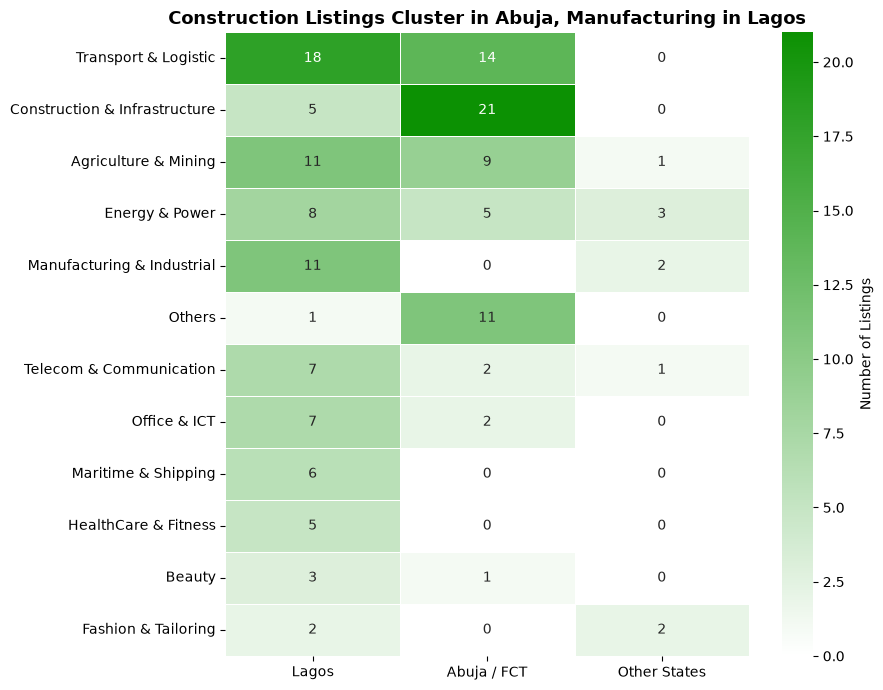

In [8]:
df_heat = df_analysis.copy()

df_heat["category"] = (
    df_heat["category"]
    .str.strip()
    .replace({"Construction & Infrastruture": "Construction & Infrastructure"})
)

df_heat["region_group"] = df_heat["region"].where(
    df_heat["region"].isin(["Lagos", "Abuja / FCT"]),
    "Other States"
)

heat_table = pd.crosstab(df_heat["category"], df_heat["region_group"])
heat_table = heat_table[["Lagos", "Abuja / FCT", "Other States"]]
heat_table = heat_table.loc[heat_table.sum(axis=1).sort_values(ascending=False).index]

print(heat_table)
print("\nTotals:")
print(heat_table.sum())

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    heat_table,
    annot=True,
    fmt="d",
    cmap=brand_cmap,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Number of Listings"},
    ax=ax
)

ax.set_title("Construction Listings Cluster in Abuja, Manufacturing in Lagos", fontsize=13, weight="bold")
ax.set_xlabel("")
ax.set_ylabel("")

plt.tight_layout()
plt.savefig("charts/07_category_region_heatmap.png", dpi=200)
plt.show()

**Insight:** The overall Lagos lead (84 listings) hides sharp differences by category. Construction & Infrastructure is concentrated in Abuja / FCT (21 of 26 listings, 80.8%), the reverse of the overall pattern. "Others" is also Abuja-heavy (11 of 12). Manufacturing & Industrial is the opposite: 11 of 13 listings are in Lagos, none in Abuja. Maritime & Shipping (6) and HealthCare & Fitness (5) are entirely Lagos-based, though these counts are small. Transport & Logistic is the most evenly split large category (18 Lagos, 14 Abuja). Outside Lagos and Abuja, listings are rare (9 in total) and appear only in Energy & Power (3), Manufacturing & Industrial (2), Fashion & Tailoring (2), Agriculture & Mining (1) and Telecom & Communication (1). Caution: these patterns describe where listings were advertised on this platform. A few sellers posting many listings could drive some of the clusters, and seller information was not collected, so this cannot be tested here.

### Chart 8: Marketplace Summary Dashboard

Saved to: charts/08_summary_dashboard.png


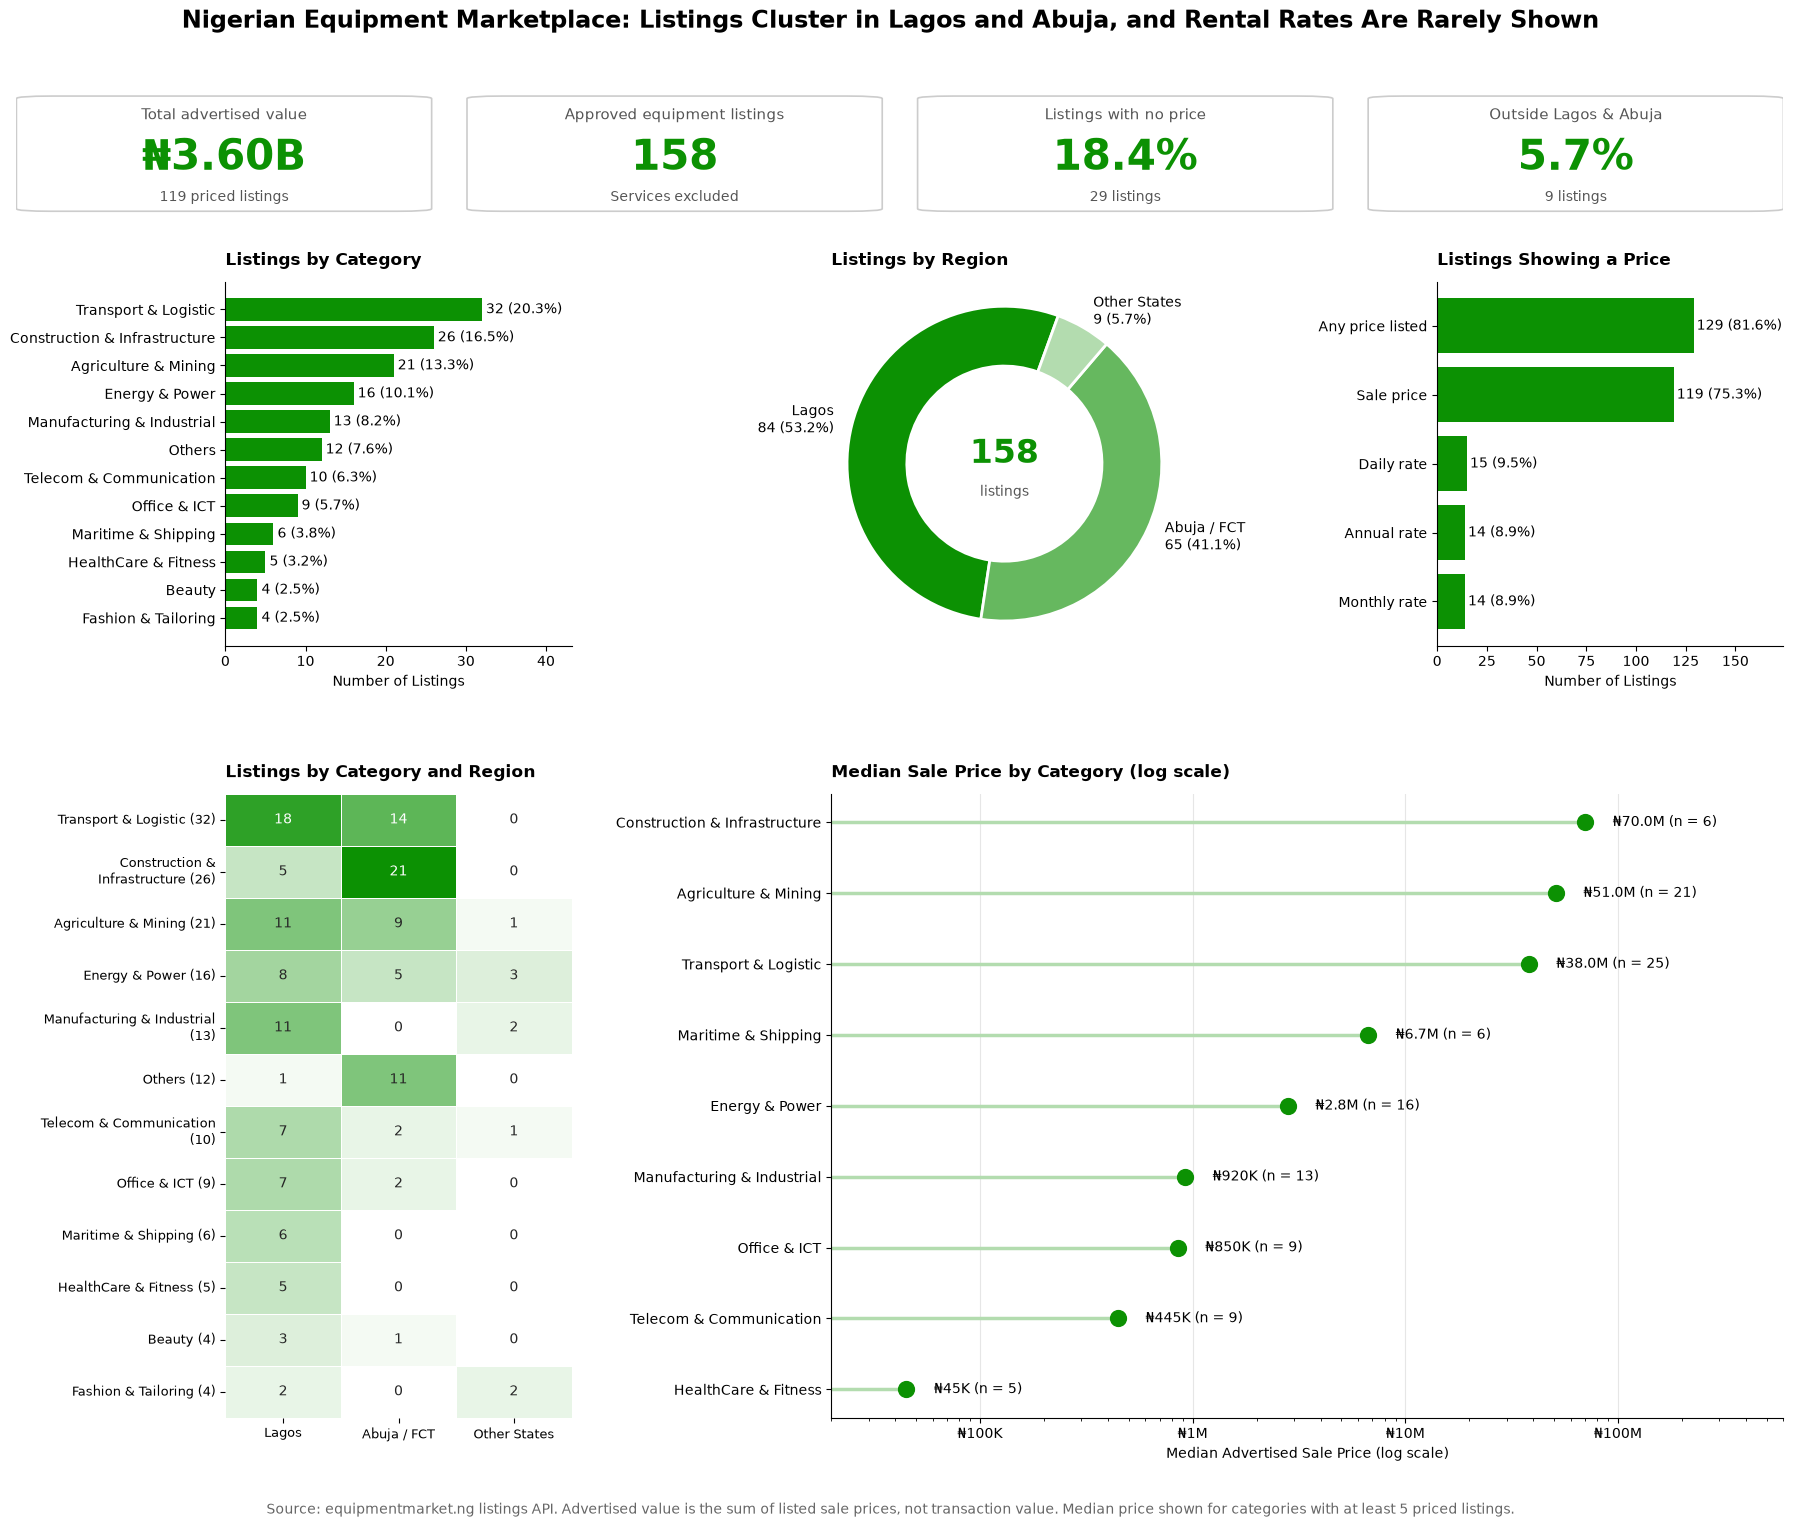

In [9]:
import os
import textwrap
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyBboxPatch
from matplotlib.ticker import FuncFormatter, NullFormatter

# ---------- Brand palette: green version (from equipmentmarket.ng) ----------
GREEN = "#0c9103"
GREEN_MID = "#66b85f"
GREEN_LIGHT = "#b3dcaf"
GREEN_DARK = "#0a5a03"
GREY = "#555555"
brand_cmap = LinearSegmentedColormap.from_list("brand_green", ["#ffffff", GREEN])

total = len(df_analysis)
price_cols = ["sale_price", "daily_rate", "monthly_rate", "annual_rate"]

def fix_cat(series):
    return series.str.strip().replace(
        {"Construction & Infrastruture": "Construction & Infrastructure"}
    )

# ---------- Data prep ----------
cat_counts = fix_cat(df_analysis["category"]).value_counts().sort_values()

region_group = df_analysis["region"].where(
    df_analysis["region"].isin(["Lagos", "Abuja / FCT"]), "Other States"
)
region_counts = region_group.value_counts().reindex(
    ["Lagos", "Abuja / FCT", "Other States"]
)

avail = {
    "Any price listed": df_analysis[price_cols].notna().any(axis=1).sum(),
    "Sale price": df_analysis["sale_price"].notna().sum(),
    "Daily rate": df_analysis["daily_rate"].notna().sum(),
    "Monthly rate": df_analysis["monthly_rate"].notna().sum(),
    "Annual rate": df_analysis["annual_rate"].notna().sum(),
}
avail = dict(sorted(avail.items(), key=lambda item: item[1]))

sale_prices = df_analysis["sale_price"].dropna()

df_price = df_analysis.dropna(subset=["sale_price"]).copy()
df_price["category"] = fix_cat(df_price["category"])
cat_price = (
    df_price.groupby("category")["sale_price"]
    .agg(median_price="median", n="count")
    .reset_index()
)
cat_price = cat_price[cat_price["n"] >= 5].sort_values("median_price")

# KPI values
total_value = sale_prices.sum()
n_priced = sale_prices.count()
no_price_n = df_analysis[price_cols].isna().all(axis=1).sum()
outside_n = (region_group == "Other States").sum()

# Heatmap table: categories down the side, three regions across the top
df_heat = df_analysis.copy()
df_heat["category"] = fix_cat(df_heat["category"])
df_heat["region_group"] = region_group
heat = pd.crosstab(df_heat["category"], df_heat["region_group"])
heat = heat[["Lagos", "Abuja / FCT", "Other States"]]
heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index]
heat.index = [
    textwrap.fill(f"{name} ({n})", 26) for name, n in zip(heat.index, heat.sum(axis=1))
]

# ---------- Helpers ----------
def label_bars(ax, bars, pad):
    for bar in bars:
        count = int(bar.get_width())
        ax.text(
            bar.get_width() + pad,
            bar.get_y() + bar.get_height() / 2,
            f"{count} ({count / total * 100:.1f}%)",
            va="center", fontsize=10
        )

def money(v):
    return f"₦{v / 1e6:.1f}M" if v >= 1e6 else f"₦{v / 1e3:.0f}K"

def naira_axis(x, pos):
    return f"₦{x / 1e6:g}M" if x >= 1e6 else f"₦{x / 1e3:g}K"

def style_panel(ax, title):
    ax.set_title(title, weight="bold", loc="left", fontsize=12, pad=12)
    ax.spines[["top", "right"]].set_visible(False)

# ---------- Layout ----------
fig = plt.figure(figsize=(19, 16), facecolor="white")

fig.suptitle(
    "Nigerian Equipment Marketplace: Listings Cluster in Lagos and Abuja, and Rental Rates Are Rarely Shown",
    fontsize=17, weight="bold", y=0.96, color="black"
)

# KPI row has its own layout, spanning the full content width
gs_kpi = fig.add_gridspec(1, 1, top=0.91, bottom=0.83, left=0.04, right=0.97)
gs = fig.add_gridspec(
    2, 3, height_ratios=[1.4, 2.4],
    hspace=0.3, wspace=0.75, top=0.79, bottom=0.08, left=0.15, right=0.97
)

# ---------- KPI tiles (white, thin grey border) ----------
ax_kpi = fig.add_subplot(gs_kpi[0, 0])
ax_kpi.axis("off")

kpis = [
    ("Total advertised value", f"₦{total_value / 1e9:.2f}B", f"{n_priced} priced listings"),
    ("Approved equipment listings", f"{total}", "Services excluded"),
    ("Listings with no price", f"{no_price_n / total * 100:.1f}%", f"{no_price_n} listings"),
    ("Outside Lagos & Abuja", f"{outside_n / total * 100:.1f}%", f"{outside_n} listings"),
]

card_w, gap = 0.235, 0.02
for i, (title, value, line) in enumerate(kpis):
    x0 = i * (card_w + gap)
    ax_kpi.add_patch(FancyBboxPatch(
        (x0, 0.05), card_w, 0.9,
        boxstyle="round,pad=0,rounding_size=0.02",
        transform=ax_kpi.transAxes,
        facecolor="white", edgecolor="#cccccc", linewidth=1.2
    ))
    cx = x0 + card_w / 2
    ax_kpi.text(cx, 0.80, title, ha="center", va="center",
                fontsize=11, color=GREY, transform=ax_kpi.transAxes)
    ax_kpi.text(cx, 0.46, value, ha="center", va="center",
                fontsize=30, weight="bold", color=GREEN, transform=ax_kpi.transAxes)
    ax_kpi.text(cx, 0.16, line, ha="center", va="center",
                fontsize=10, color=GREY, transform=ax_kpi.transAxes)

# ---------- Row 1, left: listings by category ----------
ax1 = fig.add_subplot(gs[0, 0])
bars = ax1.barh(cat_counts.index, cat_counts.values, color=GREEN)
label_bars(ax1, bars, pad=0.5)
style_panel(ax1, "Listings by Category")
ax1.set_xlabel("Number of Listings")
ax1.set_xlim(0, cat_counts.max() * 1.35)

# ---------- Row 1, middle: listings by region (doughnut) ----------
ax2 = fig.add_subplot(gs[0, 1])
region_labels = [
    f"{name}\n{int(count)} ({count / total * 100:.1f}%)"
    for name, count in region_counts.items()
]
ax2.pie(
    region_counts.values,
    labels=region_labels,
    colors=[GREEN, GREEN_MID, GREEN_LIGHT],
    startangle=70,
    counterclock=True,
    labeldistance=1.12,
    textprops={"fontsize": 10},
    wedgeprops=dict(width=0.38, edgecolor="white", linewidth=2)
)
ax2.text(0, 0.06, f"{total}", ha="center", va="center",
         fontsize=24, weight="bold", color=GREEN)
ax2.text(0, -0.18, "listings", ha="center", va="center", fontsize=10, color=GREY)
ax2.set_title("Listings by Region", weight="bold", loc="left", fontsize=12, pad=12)
ax2.axis("equal")

# ---------- Row 1, right: price availability ----------
ax3 = fig.add_subplot(gs[0, 2])
bars = ax3.barh(list(avail.keys()), list(avail.values()), color=GREEN)
label_bars(ax3, bars, pad=1.5)
style_panel(ax3, "Listings Showing a Price")
ax3.set_xlabel("Number of Listings")
ax3.set_xlim(0, max(avail.values()) * 1.35)

# ---------- Row 2, left: category by region heatmap ----------
ax4 = fig.add_subplot(gs[1, 0])
sns.heatmap(
    heat, annot=True, fmt="d", cmap=brand_cmap,
    linewidths=0.5, linecolor="white", cbar=False,
    annot_kws={"fontsize": 10}, ax=ax4
)
plt.setp(ax4.get_xticklabels(), rotation=0, fontsize=9)
plt.setp(ax4.get_yticklabels(), rotation=0, fontsize=9)
ax4.set_title("Listings by Category and Region", weight="bold", loc="left", fontsize=12, pad=12)
ax4.set_xlabel("")
ax4.set_ylabel("")

# ---------- Row 2, middle and right: median sale price (dot plot, log scale) ----------
ax5 = fig.add_subplot(gs[1, 1:])
y_pos = range(len(cat_price))
values = cat_price["median_price"].values
x_min, x_max = 2e4, 6e8

ax5.set_axisbelow(True)
ax5.grid(axis="x", color="#e6e6e6", linewidth=0.8)
ax5.hlines(y_pos, xmin=x_min, xmax=values, color=GREEN_LIGHT, linewidth=2.5)
ax5.scatter(values, y_pos, color=GREEN, s=130, zorder=3)

for y, v, n in zip(y_pos, values, cat_price["n"]):
    ax5.text(v * 1.35, y, f"{money(v)} (n = {n})", va="center", fontsize=10)

ax5.set_xscale("log")
ax5.set_xlim(x_min, x_max)
ax5.set_yticks(list(y_pos))
ax5.set_yticklabels(cat_price["category"])
ax5.xaxis.set_major_formatter(FuncFormatter(naira_axis))
ax5.xaxis.set_minor_formatter(NullFormatter())
style_panel(ax5, "Median Sale Price by Category (log scale)")
ax5.set_xlabel("Median Advertised Sale Price (log scale)")

# ---------- Footer ----------
fig.text(
    0.5, 0.02,
    "Source: equipmentmarket.ng listings API. Advertised value is the sum of listed sale prices, not transaction value. "
    "Median price shown for categories with at least 5 priced listings.",
    ha="center", fontsize=10, color="#666666"
)

# ---------- Save ----------
os.makedirs("charts", exist_ok=True)
save_path = os.path.abspath(os.path.join("charts", "08_summary_dashboard.png"))

try:
    fig.savefig(save_path, dpi=200)
    print("Saved to: charts/08_summary_dashboard.png")
except OSError as e:
    print("Save failed:", e)
    fallback = os.path.abspath("08_summary_dashboard.png")
    fig.savefig(fallback, dpi=200)
    print("Saved instead to: 08_summary_dashboard.png")

plt.show()

### Dashboard Insights

**Headline:** The 158 approved equipment listings carry about ₦3.60B in advertised sale value, but that total rests on only 119 priced listings and is driven by a small number of high-value items. Listings are concentrated in a few categories and two cities, and rental pricing is rarely shown.

**What the dashboard shows**
- **Category representation:** Transport & Logistic (32), Construction & Infrastructure (26) and Agriculture & Mining (21) make up half of all listings (79 of 158).
- **Geographic concentration:** Lagos (84, 53.2%) and Abuja / FCT (65, 41.1%) hold 94.3% of listings. Only 9 listings (5.7%) sit in the other six states combined.
- **The split differs by category:** Construction & Infrastructure is concentrated in Abuja (21 of 26 listings), while Manufacturing & Industrial is almost entirely in Lagos (11 of 13). Maritime & Shipping (6) and HealthCare & Fitness (5) are Lagos-only.
- **Price availability:** 129 listings (81.6%) show at least one price, and 119 (75.3%) show a sale price. Each rental rate type appears on fewer than 10% of listings (daily 9.5%, monthly and annual 8.9%). 29 listings (18.4%) show no price at all.
- **Price level:** Median advertised sale prices range from ₦45K (HealthCare & Fitness) to ₦70M (Construction & Infrastructure). Agriculture & Mining (₦51.0M) and Transport & Logistic (₦38.0M) follow, and both rest on larger samples (21 and 25 priced listings).

**Implications for marketplace planning**
- **Expand supply outside Lagos and Abuja.** Coverage elsewhere is very thin, which is the clearest geographic gap.
- **Get sellers to add prices, especially rental rates.** About one in five listings has no price, and rental rates are almost absent, which limits how well buyers can compare options.
- **Support thin categories.** Beauty, Fashion & Tailoring, HealthCare & Fitness and Maritime & Shipping have very few listings and may need targeted seller onboarding if the platform wants to represent them.

**Caution when reading the dashboard**
- Advertised value is the sum of listed sale prices, not transaction value, and a few high-value listings drive it.
- Several category medians rest on 5 to 9 priced listings, so treat them as indicative. The median price panel uses a log axis, where equal distances represent equal ratios, not equal amounts.
- This is a snapshot of one platform's approved listings. It shows where listings were advertised, not where equipment exists or where demand is. Seller information was not collected, so a few active sellers could be driving some of the category and regional clusters.